# Data Slayer 4.0 Legit Notebook

Objective: Mengklasifikasikan klip ujian berdurasi 1 detik (30 frame) menjadi normal (0) atau cheating (1) hanya dari pengetahuan data train (fitur DINOv3 dan pose), tanpa aturan detik dari leaderboard dan tanpa memaksa rasio cheating, menggunakan F1-Macro sebagai metrik evaluasi.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys
print(sys.version)
%pip install -q torch==2.11.0 opencv-python==5.0.0.93 scikit-learn==1.8.0 scipy==1.17.1 numpy==2.4.4 pandas==2.3.3 matplotlib==3.10.9 tqdm==4.67.3

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\leouw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.ndimage import uniform_filter1d
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA = Path("../data")
CACHE = Path("../cache/dinov3_hplus_224x400_step3_bf16")
POSE_CACHE = Path("../cache/pose_vitpose")
N_FOLDS = 5
FRAMES_PER_CLIP = 30
STEPS_PER_CLIP = 10
VIDEOS_PER_SUBJECT = 16
LINK_MAX = 3.0
LAGS = [5, 15, 50]
MAX_SHIFT = 30
BASE_STEPS = 30
C_DINO = 0.3
C_POSE = 0.1
POSE_WEIGHT = 1.0
W_AGREE = 0.25
EM_ITERS = 6
CHEAT_ACTIONS = ["Looking_Under_the_Desk", "Reading_Hidden_Notes", "Repeated_Peeking", "Using_Smartwatch"]
NORMAL_ACTIONS = ["Checking_Smartwatch", "Looking_Around", "Thinking", "Writing_Answers"]
ACTIONS = CHEAT_ACTIONS + NORMAL_ACTIONS
IS_CHEAT = np.array([a in CHEAT_ACTIONS for a in ACTIONS])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(SEED)
print(torch.__version__, DEVICE)

2.11.0+cu128 cuda


# Import datasets

In [3]:
rows = []
for path in sorted(DATA.glob("train/*/*/*.MOV")):
    view, action = path.stem.split("_", 1)
    rows.append({
        "video": f"{path.parent.parent.name}/{path.parent.name}/{path.stem}",
        "label": int(path.parent.parent.name == "cheat"),
        "subject": int(path.parent.name.split("_")[1]),
        "view": view,
        "action": action,
    })
train = pd.DataFrame(rows)
train["action_id"] = train["action"].map(ACTIONS.index)
sub = pd.read_csv(DATA / "sample_submission.csv")
eye = pd.read_csv("train_action_start_eye_all.csv")
print(train.shape, sub.shape, eye.shape)
train.head()

(416, 6) (1515, 2) (104, 3)


,video,label,subject,view,action,action_id
0,cheat/subject_1/front_Looking_Under_the_Desk,1,1,front,Looking_Under_the_Desk,0
1,cheat/subject_1/front_Reading_Hidden_Notes,1,1,front,Reading_Hidden_Notes,1
2,cheat/subject_1/front_Repeated_Peeking,1,1,front,Repeated_Peeking,2
3,cheat/subject_1/front_Using_Smartwatch,1,1,front,Using_Smartwatch,3
4,cheat/subject_1/side_Looking_Under_the_Desk,1,1,side,Looking_Under_the_Desk,0


# EDA

### Struktur train
Setiap subjek punya 16 video: 2 view x 8 aksi, satu take direkam bersamaan oleh kamera front dan side.

In [4]:
print("subjek:", train["subject"].nunique(), "| video:", len(train))
train.groupby(["subject", "view"])["action"].nunique().value_counts().rename("jumlah grup subjek-view").rename_axis("aksi unik per grup").to_frame()

subjek: 26 | video: 416


,jumlah grup subjek-view
aksi unik per grup,
8,52


### Awal aksi di train
Detik saat subjek berhenti menulis dan mulai melakukan aksi cheating, dibaca manual dari frame video train (kamera front, 104 video). Test tidak pernah dibaca manual.

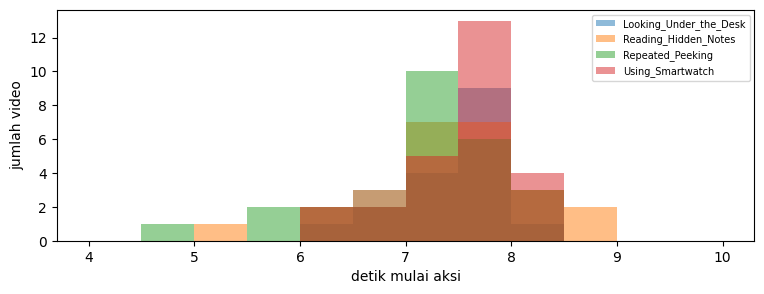

terbaca: 95 dari 104 | tidak jelas: 9


,count,min,50%,max
action,,,,
Looking_Under_the_Desk,18.0,6.25,7.75,8.25
Reading_Hidden_Notes,25.0,5.25,7.25,8.75
Repeated_Peeking,26.0,4.75,7.25,8.25
Using_Smartwatch,26.0,6.25,7.75,8.25


In [5]:
eye["action"] = eye["video"].str.split("/").str[2].str.split("_", n=1).str[1]
known = eye.dropna(subset=["start_eye"])
fig, ax = plt.subplots(figsize=(9, 3))
for action, g in known.groupby("action"):
    ax.hist(g["start_eye"], bins=np.arange(4, 10.5, 0.5), alpha=0.5, label=action)
ax.set_xlabel("detik mulai aksi")
ax.set_ylabel("jumlah video")
ax.legend(fontsize=7)
plt.show()
print(f"terbaca: {len(known)} dari {len(eye)} | tidak jelas: {eye['start_eye'].isna().sum()}")
known.groupby("action")["start_eye"].describe()[["count", "min", "50%", "max"]].round(2)

# Feature Extraction

### Fitur DINOv3 dari cache
Fitur per frame DINOv3 ViT-H+ (CLS + rata-rata patch, 2560 dimensi, 10 fps) dari baseline_cv.ipynb.

In [6]:
assert (CACHE / "test.npy").exists(), "cache DINOv3 belum ada, jalankan baseline_cv.ipynb sampai bagian Feature Extraction"
train_feats = [np.load(CACHE / "train" / (v.replace("/", "__") + ".npy")).astype(np.float32) for v in train["video"]]
clip_feats = np.load(CACHE / "test.npy").astype(np.float32)
print("video train:", len(train_feats), "| klip test:", clip_feats.shape)

video train: 416 | klip test: (1515, 10, 2560)


### Pose dari cache
17 keypoint tubuh (ViTPose) di dalam box orang (RT-DETR), 10 frame per detik, dari scripts/extract_pose.py. Setiap detik video train dipotong seperti klip test (frame 0-29, 30-59, dst).

In [7]:
assert (POSE_CACHE / "pose_test.npy").exists(), "cache pose belum ada, jalankan python scripts/extract_pose.py test train"
pose_meta = pd.read_csv(POSE_CACHE / "pose_train_s30_meta.csv")
pose_kp = np.load(POSE_CACHE / "pose_train_s30.npy")
pose_box = np.load(POSE_CACHE / "box_train_s30.npy")
pose_meta["video"] = ["cheat/" + v if l == 1 else "normal/" + v for v, l in zip(pose_meta["video"], pose_meta["label"])]
pose_meta["video"] = pose_meta["video"].str.replace(".MOV", "", regex=False)
train_pose = []
for v in train["video"]:
    idx = np.where(pose_meta["video"] == v)[0]
    idx = idx[np.argsort(pose_meta["start"].values[idx])]
    train_pose.append((pose_kp[idx].reshape(-1, 17, 3), np.repeat(pose_box[idx], STEPS_PER_CLIP, axis=0)))
test_ids = pd.read_csv(POSE_CACHE / "pose_test_meta.csv")["id"]
assert (test_ids.values == np.sort(sub["id"].values)).all()
row_of_id = {i: k for k, i in enumerate(test_ids)}
clip_kp = np.load(POSE_CACHE / "pose_test.npy")
clip_box = np.load(POSE_CACHE / "box_test.npy")
print("pose train:", len(train_pose), train_pose[0][0].shape, "| pose klip test:", clip_kp.shape)

pose train: 416 (130, 17, 3) | pose klip test: (1515, 10, 17, 3)


# Aggregate
Menyusun ulang 1.515 klip test menjadi video utuh, lalu mencari pasangan kamera front dan side dari take yang sama. Pengelompokan subjek hanya dipakai untuk mencari pasangan kamera, tidak untuk memaksa jumlah cheating.

### Penyambungan klip
Frame terakhir sebuah klip hampir sama dengan frame pertama klip lanjutannya. Dua klip disambung jika keduanya saling menjadi pasangan terdekat dan selisih pikselnya di bawah LINK_MAX.

In [8]:
def load_small(args):
    seq, k = args
    img = cv2.imread(str(DATA / "test" / seq / f"{k:02d}.jpg"), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(img, (160, 90), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()


with ThreadPoolExecutor(16) as ex:
    first = torch.tensor(np.stack(list(ex.map(load_small, [(s, 1) for s in sub["id"]])))).to(DEVICE)
    last = torch.tensor(np.stack(list(ex.map(load_small, [(s, FRAMES_PER_CLIP) for s in sub["id"]])))).to(DEVICE)
dist = torch.cdist(last, first, p=1) / first.shape[1]
dist.fill_diagonal_(float("inf"))
succ = dist.argmin(1).cpu().numpy()
pred = dist.argmin(0).cpu().numpy()
succ_dist = dist.min(1).values.cpu().numpy()
n_clips = len(sub)
linked = (pred[succ] == np.arange(n_clips)) & (succ_dist < LINK_MAX)
next_clip = {i: succ[i] for i in range(n_clips) if linked[i]}
has_prev = set(next_clip.values())
chains = []
for i in range(n_clips):
    if i not in has_prev:
        chain = [i]
        while chain[-1] in next_clip:
            chain.append(next_clip[chain[-1]])
        chains.append(chain)
assert sum(len(c) for c in chains) == n_clips
test_feats = [clip_feats[c].reshape(-1, clip_feats.shape[-1]) for c in chains]
test_pose = [(clip_kp[[row_of_id[sub["id"][k]] for k in c]].reshape(-1, 17, 3),
              np.repeat(clip_box[[row_of_id[sub["id"][k]] for k in c]], STEPS_PER_CLIP, axis=0)) for c in chains]
print("video test:", len(chains), "| panjang (detik):", min(map(len, chains)), "-", max(map(len, chains)))

video test: 96 | panjang (detik): 14 - 19


### View, subjek, dan pasangan kamera
- view: mengikuti view video train yang paling mirip.
- subjek: clustering Ward per view menjadi jumlah video / 16 kelompok, lalu kelompok front dan side dicocokkan dari kemiripan waktu gerakan.
- pasangan kamera: di dalam satu subjek, video front dipasangkan satu-satu dengan video side yang naik-turun gerakannya paling mirip (korelasi silang profil gerakan).

In [9]:
def normalize(x):
    return x / np.linalg.norm(x, axis=-1, keepdims=True)


def motion_profile(feats, k=5):
    energy = np.linalg.norm(feats[k:] - feats[:-k], axis=1)
    return (energy - energy.mean()) / (energy.std() + 1e-9)


def timing_match(a, b):
    best = -1.0
    for shift in range(-MAX_SHIFT, MAX_SHIFT + 1):
        x, y = (a[shift:], b) if shift >= 0 else (a, b[-shift:])
        n = min(len(x), len(y))
        if n > 60:
            best = max(best, float(np.dot(x[:n], y[:n]) / n))
    return best


def timing_matrix(profiles, front_idx, side_idx):
    return np.array([[timing_match(profiles[i], profiles[j]) for j in side_idx] for i in front_idx])


def pair_cameras(profiles, subjects, views):
    partner = np.full(len(subjects), -1)
    for s in np.unique(subjects):
        f = np.where((subjects == s) & (views == "front"))[0]
        d = np.where((subjects == s) & (views == "side"))[0]
        rows, cols = linear_sum_assignment(-timing_matrix(profiles, f, d))
        partner[f[rows]], partner[d[cols]] = d[cols], f[rows]
    return partner


train_mean = np.stack([f.mean(0) for f in train_feats])
test_mean = np.stack([f.mean(0) for f in test_feats])
center = train_mean.mean(0)
nearest = (normalize(test_mean - center) @ normalize(train_mean - center).T).argmax(1)
test_videos = pd.DataFrame({"n_clips": [len(c) for c in chains], "view": train["view"].values[nearest]})
n_test_subjects = len(chains) // VIDEOS_PER_SUBJECT
test_videos["cluster"] = -1
for view in ["front", "side"]:
    idx = np.where(test_videos["view"] == view)[0]
    test_videos.loc[idx, "cluster"] = fcluster(linkage(normalize(test_mean[idx] - test_mean[idx].mean(0)), "ward"), n_test_subjects, "maxclust")
test_profiles = [motion_profile(f) for f in test_feats]
group_idx = {(v, k): np.where((test_videos["view"] == v) & (test_videos["cluster"] == k))[0] for v in ["front", "side"] for k in range(1, n_test_subjects + 1)}
sim = np.zeros((n_test_subjects, n_test_subjects))
for a in range(n_test_subjects):
    for b in range(n_test_subjects):
        m = timing_matrix(test_profiles, group_idx[("front", a + 1)], group_idx[("side", b + 1)])
        sim[a, b] = m[linear_sum_assignment(-m)].mean()
front_k, side_k = linear_sum_assignment(-sim)
subject_of = {("front", f + 1): i + 1 for i, f in enumerate(front_k)} | {("side", s + 1): i + 1 for i, s in enumerate(side_k)}
test_videos["subject"] = [subject_of[(v, k)] for v, k in zip(test_videos["view"], test_videos["cluster"])]
test_partner = pair_cameras(test_profiles, test_videos["subject"].values, test_videos["view"].values)
train_profiles = [motion_profile(f) for f in train_feats]
train_partner = pair_cameras(train_profiles, train["subject"].values, train["view"].values)
true_partner = np.array([np.where((train["subject"] == s) & (train["action"] == a) & (train["view"] != v))[0][0]
                         for s, a, v in zip(train["subject"], train["action"], train["view"])])
print("subjek test:", n_test_subjects, "| video per subjek-view:", test_videos.groupby(["subject", "view"]).size().unique())
print(f"pasangan kamera benar di train: {(train_partner == true_partner).mean():.3f}")

subjek test: 6 | video per subjek-view: [8]
pasangan kamera benar di train: 0.957


# Feature Engineering

### Sinyal gerakan per frame
Mengubah 17 keypoint menjadi sinyal gerakan yang bisa dibaca, dinormalisasi dengan tinggi box orang:
- head_yaw: posisi hidung terhadap kedua telinga, besar saat kepala menoleh.
- head_down: tinggi hidung terhadap bahu, besar saat kepala menunduk.
- wrist_gap: jarak kedua pergelangan tangan, kecil saat satu tangan memegang jam di tangan lain.
- hand_face: jarak pergelangan terdekat ke hidung, kecil saat tangan dekat wajah.
- lean: posisi tengah bahu, berubah saat badan condong.

In [10]:
NOSE, LEYE, REYE, LEAR, REAR, LSH, RSH, LEL, REL, LWR, RWR, LHIP, RHIP = 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12


def pose_series(kp, box):
    h = box[:, 3:4] + 1e-6
    x, y, s = (kp[..., 0] - box[:, 0:1]) / h, (kp[..., 1] - box[:, 1:2]) / h, kp[..., 2]
    msx, msy = (x[:, LSH] + x[:, RSH]) / 2, (y[:, LSH] + y[:, RSH]) / 2
    sh_w = np.abs(x[:, LSH] - x[:, RSH]) + 1e-3
    d_l = np.hypot(x[:, LWR] - x[:, NOSE], y[:, LWR] - y[:, NOSE])
    d_r = np.hypot(x[:, RWR] - x[:, NOSE], y[:, RWR] - y[:, NOSE])
    return pd.DataFrame({
        "head_yaw": (x[:, NOSE] - (x[:, LEAR] + x[:, REAR]) / 2) / sh_w,
        "head_down": y[:, NOSE] - msy,
        "eye_yaw": (x[:, NOSE] - (x[:, LEYE] + x[:, REYE]) / 2) / sh_w,
        "ear_vis": s[:, LEAR] - s[:, REAR],
        "wrist_gap": np.hypot(x[:, LWR] - x[:, RWR], y[:, LWR] - y[:, RWR]),
        "hand_face": np.minimum(d_l, d_r),
        "lwr_dx": x[:, LWR] - msx, "lwr_dy": y[:, LWR] - msy,
        "rwr_dx": x[:, RWR] - msx, "rwr_dy": y[:, RWR] - msy,
        "lel_dy": y[:, LEL] - msy, "rel_dy": y[:, REL] - msy,
        "wrist_score": np.minimum(s[:, LWR], s[:, RWR]),
        "lean_x": msx, "lean_y": msy, "sh_tilt": y[:, LSH] - y[:, RSH], "sh_w": sh_w,
        "head_speed": np.r_[0, np.hypot(np.diff(x[:, NOSE]), np.diff(y[:, NOSE]))],
        "hand_speed": np.r_[0, (np.hypot(np.diff(x[:, LWR]), np.diff(y[:, LWR])) + np.hypot(np.diff(x[:, RWR]), np.diff(y[:, RWR]))) / 2],
    })


train_series = [pose_series(kp, box) for kp, box in train_pose]
test_series = [pose_series(kp, box) for kp, box in test_pose]
train_series[0].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
head_yaw,0.084,0.041,0.020,0.146
head_down,-0.037,0.048,-0.113,0.025
eye_yaw,-0.023,0.018,-0.057,0.004
ear_vis,-0.235,0.065,-0.366,-0.109
wrist_gap,0.243,0.176,0.052,0.523
hand_face,0.372,0.070,0.277,0.484
lwr_dx,0.327,0.103,0.213,0.514
lwr_dy,0.290,0.030,0.216,0.328
rwr_dx,0.089,0.075,-0.021,0.174
rwr_dy,0.333,0.021,0.292,0.372


### Gerakan khas per aksi
Rata-rata perubahan setiap sinyal terhadap 3 detik pertama videonya (saat subjek masih menulis), per detik dan per aksi di train. Ini menunjukkan gerakan apa yang membedakan setiap aksi dan kapan gerakan itu muncul.

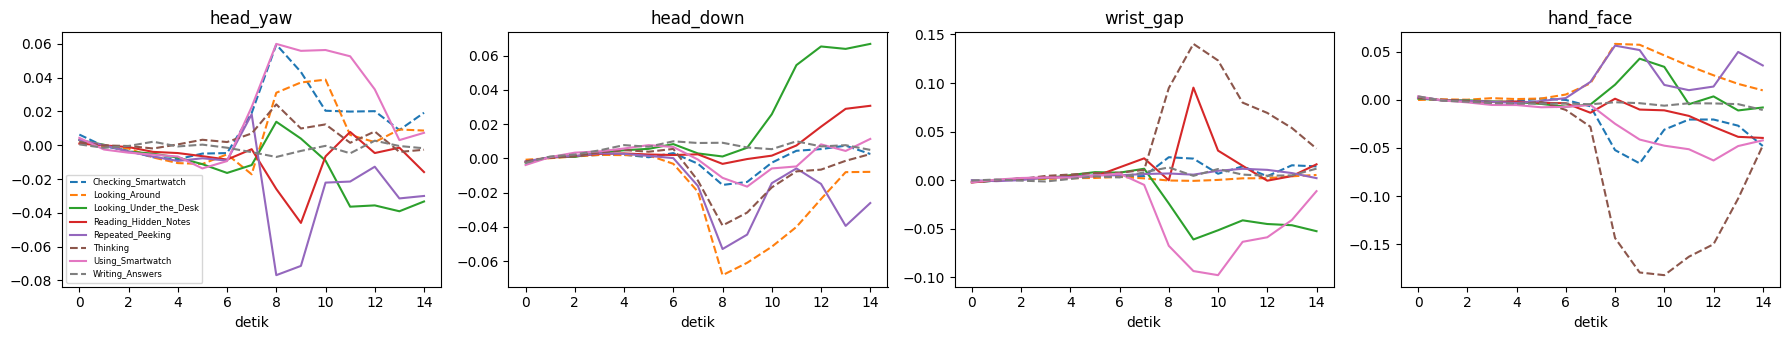

,head_yaw,head_down,eye_yaw,wrist_gap,hand_face,lean_y,head_speed,hand_speed
action,,,,,,,,
Checking_Smartwatch,1.461,-0.008,-0.089,-0.004,-0.047,0.002,0.004,0.004
Looking_Around,-0.376,-0.050,0.126,-0.001,0.049,0.013,0.007,0.001
Looking_Under_the_Desk,-0.697,0.034,-0.297,-0.040,0.006,-0.023,0.005,0.009
Reading_Hidden_Notes,-0.772,0.006,-0.067,0.046,-0.020,-0.011,0.008,0.014
Repeated_Peeking,-0.936,-0.038,0.029,0.012,0.042,0.010,0.009,0.002
Thinking,1.299,-0.028,0.112,0.105,-0.155,0.013,0.005,0.005
Using_Smartwatch,-0.029,-0.013,-0.209,-0.109,-0.057,0.010,0.003,0.006
Writing_Answers,-0.153,0.011,0.002,0.010,-0.015,-0.009,0.001,0.001


In [11]:
SHOW = ["head_yaw", "head_down", "wrist_gap", "hand_face"]


def per_second_change(series, n_seconds=15):
    base = series.iloc[:BASE_STEPS].mean()
    sec = (series - base).groupby(np.arange(len(series)) // STEPS_PER_CLIP).mean()
    return sec.reindex(range(n_seconds))


change = pd.concat([per_second_change(s).assign(action=a, second=range(15)) for s, a in zip(train_series, train["action"])])
fig, axes = plt.subplots(1, len(SHOW), figsize=(18, 3.5), sharex=True)
for ax, col in zip(axes, SHOW):
    for action, g in change.groupby("action"):
        ax.plot(g.groupby("second")[col].median(), label=action, ls="-" if action in CHEAT_ACTIONS else "--")
    ax.set_title(col)
    ax.set_xlabel("detik")
axes[0].legend(fontsize=6)
plt.tight_layout()
plt.show()
late = change[change["second"].between(8, 12)].groupby("action")[[c for c in train_series[0].columns]].mean()
late.loc[:, ["head_yaw", "head_down", "eye_yaw", "wrist_gap", "hand_face", "lean_y", "head_speed", "hand_speed"]].round(3)

### Cek pola yang sama di test
Pengecekan saja, tidak dipakai untuk prediksi: perubahan sinyal per detik di semua video test dibandingkan dengan semua video train. Jika polanya sama (datar di awal lalu berubah setelah sekitar detik ke-7), pengukuran dari train juga bermakna di test.

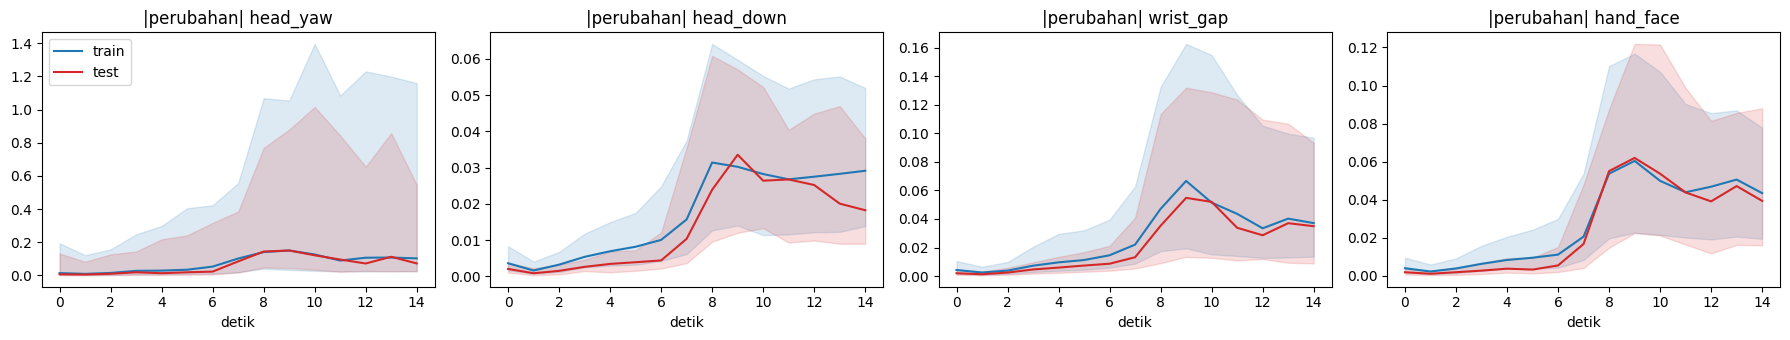

In [12]:
test_change = pd.concat([per_second_change(s).assign(second=range(15)) for s in test_series])
fig, axes = plt.subplots(1, len(SHOW), figsize=(18, 3.5), sharex=True)
for ax, col in zip(axes, SHOW):
    for name, df, color in [("train", change, "C0"), ("test", test_change, "C3")]:
        q = df.groupby("second")[col].apply(lambda v: v.abs().quantile([0.25, 0.5, 0.75])).unstack()
        ax.plot(q[0.5], color=color, label=name)
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.15)
    ax.set_title(f"|perubahan| {col}")
    ax.set_xlabel("detik")
axes[0].legend()
plt.tight_layout()
plt.show()

### Fitur per video
Merangkum satu video menjadi satu vektor:
- DINOv3: mean, std, dan std selisih fitur pada jarak 0,5, 1,5 dan 5 detik.
- pose: untuk setiap sinyal, mean, std, rata-rata perubahan antar frame, serta nilai maksimum dan minimum relatif terhadap 3 detik pertama.

In [13]:
def dino_vector(feats):
    return np.concatenate([feats.mean(0), feats.std(0)] + [(feats[k:] - feats[:-k]).std(0) for k in LAGS])


def pose_vector(series):
    base = series.iloc[:BASE_STEPS].mean()
    rel = series - base
    return np.concatenate([series.mean(), series.std(), series.diff().abs().mean(), rel.max(), rel.min(), rel.iloc[BASE_STEPS:].mean()])


X_dino = np.stack([dino_vector(f) for f in train_feats])
X_dino_test = np.stack([dino_vector(f) for f in test_feats])
X_pose = np.nan_to_num(np.stack([pose_vector(s) for s in train_series]))
X_pose_test = np.nan_to_num(np.stack([pose_vector(s) for s in test_series]))
y_action = train["action_id"].values
y_label = train["label"].values
print(X_dino.shape, X_pose.shape, X_dino_test.shape, X_pose_test.shape)

(416, 12800) (416, 114) (96, 12800) (96, 114)


# Preprocessing

### Pembagian fold per subjek
Semua video dari satu subjek berada di fold yang sama, sehingga skor validasi mengukur kemampuan model pada orang yang belum pernah dilihat.

In [14]:
train["fold"] = -1
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, val_idx) in enumerate(splitter.split(train, train["action_id"], train["subject"])):
    train.loc[val_idx, "fold"] = fold
train.groupby("fold").agg(subjek=("subject", "nunique"), video=("video", "count"), cheat=("label", "mean"))

,subjek,video,cheat
fold,,,
0,6,96,0.5
1,5,80,0.5
2,5,80,0.5
3,5,80,0.5
4,5,80,0.5


### Penyesuaian per orang
Fitur setiap video dikurangi rata-rata fitur semua video orang yang sama dari kamera yang sama, sehingga model melihat apa yang berbeda dari kebiasaan orang itu, bukan pakaian, ukuran badan, atau posisi duduknya. Di test, orang diambil dari pengelompokan subjek di atas, tanpa label.

In [15]:
def per_person(X, groups):
    X = X.copy()
    for g in np.unique(groups):
        k = groups == g
        X[k] = X[k] - X[k].mean(0)
    return X


train_groups = (train["subject"].astype(str) + "_" + train["view"]).values
test_groups = (test_videos["subject"].astype(str) + "_" + test_videos["view"]).values
X_dino, X_pose = per_person(X_dino, train_groups), per_person(X_pose, train_groups)
X_dino_test, X_pose_test = per_person(X_dino_test, test_groups), per_person(X_pose_test, test_groups)
print("grup train:", len(np.unique(train_groups)), "| grup test:", len(np.unique(test_groups)), "| video per grup test:", np.unique(pd.Series(test_groups).value_counts()))

grup train: 52 | grup test: 12 | video per grup test: [8]


# Classifier Models

### Logistic Regression DINOv3 dan pose
Dua model 8 aksi yang terpisah, satu dari fitur DINOv3 (apa yang terlihat) dan satu dari fitur pose (bagaimana tubuh bergerak).

In [16]:
def make_model(c):
    return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000))


def oof_proba(X, c):
    out = np.zeros((len(train), len(ACTIONS)))
    for fold in range(N_FOLDS):
        tr, va = (train["fold"] != fold).values, (train["fold"] == fold).values
        out[va] = make_model(c).fit(X[tr], y_action[tr]).predict_proba(X[va])
    return out


oof_dino = oof_proba(X_dino, C_DINO)
oof_pose = oof_proba(X_pose, C_POSE)
for name, p in [("DINOv3", oof_dino), ("pose", oof_pose)]:
    print(f"{name}: akurasi 8 aksi {(p.argmax(1) == y_action).mean():.4f} | F1-Macro video {f1_score(y_label, p[:, :4].sum(1) > 0.5, average='macro'):.4f}")

DINOv3: akurasi 8 aksi 0.8341 | F1-Macro video 0.8918
pose: akurasi 8 aksi 0.7885 | F1-Macro video 0.8341


### Gabungan model dan dua kamera
Log peluang kedua model dijumlahkan, lalu log peluang video front dan side dari take yang sama juga dijumlahkan karena keduanya merekam aksi yang sama. Video dianggap cheating jika peluang 4 aksi cheating di atas 0,5, tanpa memaksa jumlah cheating per subjek.

In [17]:
def combine(p_dino, p_pose, partner):
    lp = np.log(p_dino + 1e-9) + POSE_WEIGHT * np.log(p_pose + 1e-9)
    if partner is not None:
        lp = lp + lp[partner]
    p = np.exp(lp - lp.max(1, keepdims=True))
    return p / p.sum(1, keepdims=True)


variants = {
    "DINOv3": combine(oof_dino, oof_dino * 0 + 1, None),
    "pose": combine(oof_pose ** 0, oof_pose, None),
    "DINOv3 + pose": combine(oof_dino, oof_pose, None),
    "DINOv3 + pose + dua kamera": combine(oof_dino, oof_pose, train_partner),
}
scores = pd.DataFrame({name: {"F1-Macro video": f1_score(y_label, p[:, :4].sum(1) > 0.5, average="macro"),
                              "akurasi 8 aksi": (p.argmax(1) == y_action).mean()} for name, p in variants.items()}).T.round(4)
oof_final = variants["DINOv3 + pose + dua kamera"]
scores

,F1-Macro video,akurasi 8 aksi
DINOv3,0.8918,0.8341
pose,0.8341,0.7885
DINOv3 + pose,0.9110,0.8798
DINOv3 + pose + dua kamera,0.9423,0.9038


### Pasangan kamera dengan kesepakatan aksi
Front dan side satu take merekam aksi yang sama, jadi pasangan dipilih dari kecocokan waktu gerakan ditambah kemiripan peluang 8 aksi kedua video (jumlah akar perkalian peluangnya). Bobot kesepakatan dipilih dari train.

In [18]:
def pair_cameras_agree(profiles, probs, subjects, views, w):
    partner = np.full(len(subjects), -1)
    for s in np.unique(subjects):
        f = np.where((subjects == s) & (views == "front"))[0]
        d = np.where((subjects == s) & (views == "side"))[0]
        agree = np.sqrt(probs[f][:, None, :] * probs[d][None, :, :]).sum(-1)
        rows, cols = linear_sum_assignment(-(timing_matrix(profiles, f, d) + w * agree))
        partner[f[rows]], partner[d[cols]] = d[cols], f[rows]
    return partner


one_camera_train = combine(oof_dino, oof_pose, None)
one_camera_test = combine(make_model(C_DINO).fit(X_dino, y_action).predict_proba(X_dino_test),
                          make_model(C_POSE).fit(X_pose, y_action).predict_proba(X_pose_test), None)
old_train_partner, old_test_partner = train_partner.copy(), test_partner.copy()
train_partner = pair_cameras_agree(train_profiles, one_camera_train, train["subject"].values, train["view"].values, W_AGREE)
test_partner = pair_cameras_agree(test_profiles, one_camera_test, test_videos["subject"].values, test_videos["view"].values, W_AGREE)
oof_final = combine(oof_dino, oof_pose, train_partner)
pd.DataFrame({
    "pasangan benar di train": [(old_train_partner == true_partner).mean(), (train_partner == true_partner).mean()],
    "F1-Macro video": [f1_score(y_label, variants["DINOv3 + pose + dua kamera"][:, :4].sum(1) > 0.5, average="macro"),
                       f1_score(y_label, oof_final[:, :4].sum(1) > 0.5, average="macro")],
    "pasangan test berubah": [0, int((test_partner != old_test_partner).sum())],
}, index=["waktu gerakan saja", "waktu gerakan + kesepakatan aksi"]).round(4)

,pasangan benar di train,F1-Macro video,pasangan test berubah
waktu gerakan saja,0.9567,0.9423,0
waktu gerakan + kesepakatan aksi,1.0000,0.9519,8


### Detektor awal aksi
Model per frame "menulis atau aksi" pada fitur DINOv3 relatif terhadap 3 detik pertama, dilatih bergantian (hard EM): tebak detik mulai setiap video train, latih model, lalu geser tebakan ke satu titik perpindahan yang paling cocok. Front dan side dari take yang sama memakai satu titik mulai yang sama (digeser jeda kameranya). Batas pencarian dan tebakan awal diambil dari detik mulai yang dibaca di train.

In [19]:
def frames_rel(feats):
    return uniform_filter1d(feats - feats[:BASE_STEPS].mean(0), STEPS_PER_CLIP, axis=0)


def fit_frames(xs, ys, c=0.003, iters=150):
    X = torch.tensor(np.concatenate(xs)).to(DEVICE)
    y = torch.tensor(np.concatenate(ys), dtype=torch.float32).to(DEVICE)
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X = (X - mu) / sd
    w = torch.zeros(X.shape[1], device=DEVICE, requires_grad=True)
    b = torch.zeros(1, device=DEVICE, requires_grad=True)
    opt = torch.optim.LBFGS([w, b], max_iter=iters, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(X @ w + b, y) + (w ** 2).sum() / (2 * c * len(y))
        loss.backward()
        return loss

    opt.step(closure)
    return lambda Z: ((torch.tensor(Z).to(DEVICE) - mu) / sd @ w + b).detach().cpu().numpy()


def switch_cost(logit):
    l0 = np.logaddexp(0, logit)
    c0, c1 = np.r_[0, np.cumsum(l0)], np.r_[0, np.cumsum(l0 - logit)]
    return c0 + c1[-1] - c1


def best_switch(logit):
    k = np.arange(LO, min(HI, len(logit) - STEPS_PER_CLIP) + 1)
    return int(k[np.argmin(switch_cost(logit)[k])]) if len(k) else INIT


def camera_lag(a, b, max_lag=40):
    ea, eb = motion_profile(a), motion_profile(b)
    best = (-9.0, 0)
    for lag in range(-max_lag, max_lag + 1):
        x, y = (ea[lag:], eb) if lag >= 0 else (ea, eb[-lag:])
        n = min(len(x), len(y))
        best = max(best, (float(np.dot(x[:n], y[:n]) / n), lag))
    return best


def joint_switch(logit_f, logit_s, lag):
    cf, cs = switch_cost(logit_f), switch_cost(logit_s)
    best = (np.inf, None)
    for t in range(LO, min(HI, len(logit_f) - STEPS_PER_CLIP) + 1):
        u = t - lag
        if LO - 15 <= u <= min(HI + 15, len(logit_s) - STEPS_PER_CLIP) and cf[t] + cs[u] < best[0]:
            best = (cf[t] + cs[u], t)
    return best[1]


def find_starts(model, rel, idx, pairs):
    logits = {i: model(rel[i]) for i in idx}
    out = {i: best_switch(logits[i]) for i in idx}
    for i, j, lag in pairs:
        if i in logits and j in logits:
            t = joint_switch(logits[i], logits[j], lag)
            if t is not None:
                out[i], out[j] = t, t - lag
    return out


def camera_pairs(feats, partner, views, keep):
    pairs = []
    for i in np.where(views == "front")[0]:
        j = partner[i]
        if keep[i] and keep[j]:
            corr, lag = camera_lag(feats[i], feats[j])
            if corr > 0.5:
                pairs.append((i, j, lag))
    return pairs


def train_start_model(idx, pairs):
    starts = {i: INIT for i in idx if train["action"][i] != "Writing_Answers"}
    for _ in range(EM_ITERS):
        model = fit_frames([train_rel[i] for i in idx],
                           [(np.arange(len(train_rel[i])) >= starts.get(i, 10 ** 6)).astype(np.float32) for i in idx])
        starts = find_starts(model, train_rel, list(starts), pairs)
    return model


train_rel = [frames_rel(f) for f in train_feats]
is_action = (train["action"] != "Writing_Answers").values
train_pairs = camera_pairs(train_feats, true_partner, train["view"].values, is_action)
eye_start = train["video"].map(dict(zip(eye["video"], eye["start_eye"]))).values
for i, j, lag in train_pairs:
    eye_start[j] = eye_start[i] - lag / STEPS_PER_CLIP
LO = int(np.floor((np.nanmin(eye_start) - 1) * STEPS_PER_CLIP))
HI = int(np.ceil((np.nanmax(eye_start) + 1) * STEPS_PER_CLIP))
INIT = int(np.nanmedian(eye_start) * STEPS_PER_CLIP)
lags = np.array([lag for _, _, lag in train_pairs]) / STEPS_PER_CLIP
print(f"jeda kamera front -> side di train: median {np.median(lags):+.1f} detik, 90% di antara {np.percentile(lags, 5):+.1f} dan {np.percentile(lags, 95):+.1f} detik")
oof_start = np.zeros(len(train))
for fold in range(N_FOLDS):
    tr = np.where(train["fold"] != fold)[0]
    va = np.where(train["fold"] == fold)[0]
    model = train_start_model(list(tr), [p for p in train_pairs if p[0] in set(tr)])
    va_pairs = camera_pairs(train_feats, train_partner, train["view"].values, np.isin(np.arange(len(train)), va))
    for i, t in find_starts(model, train_rel, list(va), va_pairs).items():
        oof_start[i] = t / STEPS_PER_CLIP
err = (oof_start - eye_start)[(y_label == 1) & ~np.isnan(eye_start)]
print(f"jendela pencarian {LO / 10:.1f}-{HI / 10:.1f} detik, tebakan awal {INIT / 10:.2f} detik")
print(f"error awal aksi (video cheating, dibanding bacaan manual): median {np.median(np.abs(err)):.2f} detik | dalam 1 detik {np.mean(np.abs(err) <= 1):.2f} | lebih dari 2 detik {int(np.sum(np.abs(err) > 2))}")

jeda kamera front -> side di train: median -0.5 detik, 90% di antara -1.0 dan +0.2 detik


jendela pencarian 3.2-11.1 detik, tebakan awal 7.70 detik
error awal aksi (video cheating, dibanding bacaan manual): median 0.25 detik | dalam 1 detik 0.88 | lebih dari 2 detik 12


### CV per klip
Skor yang sama dengan leaderboard: setiap detik video train dinilai sendiri. Jawaban per detik: klip video cheating berlabel 1 jika sebagian besar klip ada setelah detik mulai yang dibaca manual. Video cheating yang detik mulainya tidak terbaca tidak ikut dinilai.

In [20]:
def clip_labels(video_cheat, start, n):
    pos = np.arange(n)
    return (video_cheat & (pos + 0.5 >= start)).astype(int)


rows = []
for i in range(len(train)):
    if y_label[i] == 1 and np.isnan(eye_start[i]):
        continue
    n = len(train_feats[i]) // STEPS_PER_CLIP
    truth = clip_labels(y_label[i] == 1, eye_start[i], n)
    rows.append(pd.DataFrame({
        "truth": truth,
        "seluruh video": np.full(n, int(oof_final[i, :4].sum() > 0.5)),
        "detektor awal aksi": clip_labels(oof_final[i, :4].sum() > 0.5, oof_start[i], n),
        "detektor awal aksi, label video benar": clip_labels(y_label[i] == 1, oof_start[i], n),
    }))
clips = pd.concat(rows)
pd.Series({c: f1_score(clips["truth"], clips[c], average="macro") for c in clips.columns[1:]}, name="F1-Macro per klip").round(4).to_frame()

,F1-Macro per klip
seluruh video,0.7140
detektor awal aksi,0.9486
"detektor awal aksi, label video benar",0.9778


# Submission

In [21]:
test_proba = combine(make_model(C_DINO).fit(X_dino, y_action).predict_proba(X_dino_test),
                     make_model(C_POSE).fit(X_pose, y_action).predict_proba(X_pose_test), test_partner)
test_videos["p_cheat"] = test_proba[:, :4].sum(1)
test_videos["action_pred"] = [ACTIONS[a] for a in test_proba.argmax(1)]
start_model = train_start_model(list(range(len(train))), train_pairs)
test_rel = [frames_rel(f) for f in test_feats]
test_pairs = camera_pairs(test_feats, test_partner, test_videos["view"].values, np.ones(len(test_feats), bool))
test_videos["start"] = pd.Series(find_starts(start_model, test_rel, list(range(len(test_feats))), test_pairs)) / STEPS_PER_CLIP
labels = np.zeros(n_clips, int)
for vid, chain in enumerate(chains):
    labels[chain] = clip_labels(test_videos["p_cheat"][vid] > 0.5, test_videos["start"][vid], len(chain))
Path("submissions").mkdir(exist_ok=True)
submission = pd.DataFrame({"id": sub["id"], "label": labels})
submission.to_csv("submissions/main_legit.csv", index=False)
print("video cheating:", int((test_videos["p_cheat"] > 0.5).sum()), "dari", len(test_videos), "| porsi klip cheating:", submission["label"].mean().round(3))
submission.head()

video cheating: 50 dari 96 | porsi klip cheating: 0.267


,id,label
0,test_seq_00001,0
1,test_seq_00002,0
2,test_seq_00003,0
3,test_seq_00004,0
4,test_seq_00005,0
